# Deadlock Guardian
### OS Resource Management, Detection & Recovery System

**Components demonstrated in this notebook:**
1. Resource Allocation Graph (RAG) visualization — NetworkX + Matplotlib
2. Banker's Algorithm — deadlock **avoidance**
3. Cycle / matrix-reduction detection — deadlock **detection**
4. Cost-based victim selection — deadlock **recovery**
5. Full simulation comparing a system *with* avoidance vs *without* it

---


In [1]:
import sys
sys.path.insert(0, '..')

from src.resource_system import ResourceSystem
from src.rag import build_rag, build_wait_for_graph, draw_rag
from src.detection import find_cycle, cycle_detect, detect_deadlock_multi_instance
from src.victim_selection import ProcessProfile, compute_costs, select_victim, recover_until_safe

import matplotlib.pyplot as plt
%matplotlib inline


## 1. Resource Allocation Graph (RAG)

We model processes (circles) and resources (squares).
- **Assignment edge** `R -> P`: resource R is currently held by process P
- **Request edge** `P -> R`: process P is waiting for a unit of resource R

A single-instance system is deadlocked **iff** this graph's *wait-for graph* contains a cycle.


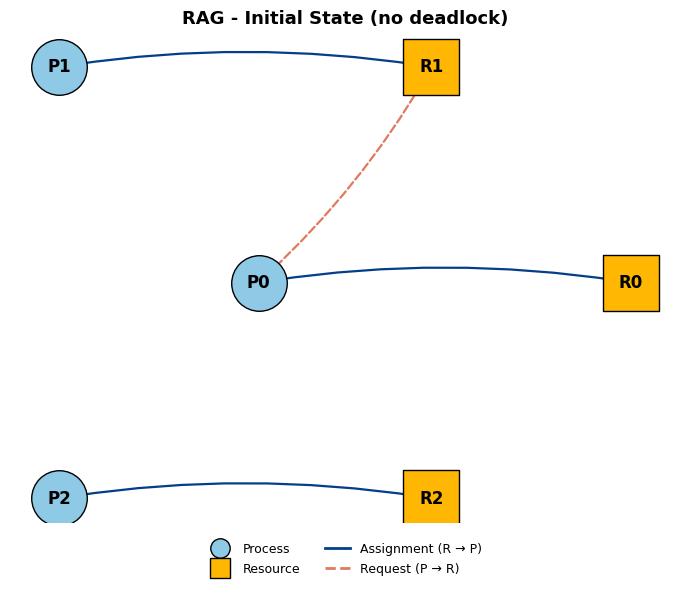

In [2]:
# A simple 3-process, 3-resource single-instance scenario (no deadlock yet)
allocation = [
    [1, 0, 0],   # P0 holds R0
    [0, 1, 0],   # P1 holds R1
    [0, 0, 1],   # P2 holds R2
]
request = [
    [0, 1, 0],   # P0 wants R1
    [0, 0, 0],   # P1 wants nothing yet
    [0, 0, 0],   # P2 wants nothing yet
]

rag = build_rag(allocation, request)
fig = draw_rag(rag, title="RAG - Initial State (no deadlock)")
plt.savefig('../images/rag_initial.png', dpi=150, bbox_inches='tight')
plt.show()


Deadlocked? True
Cycle: ['P0', 'R1', 'P1', 'R2', 'P2', 'R0']


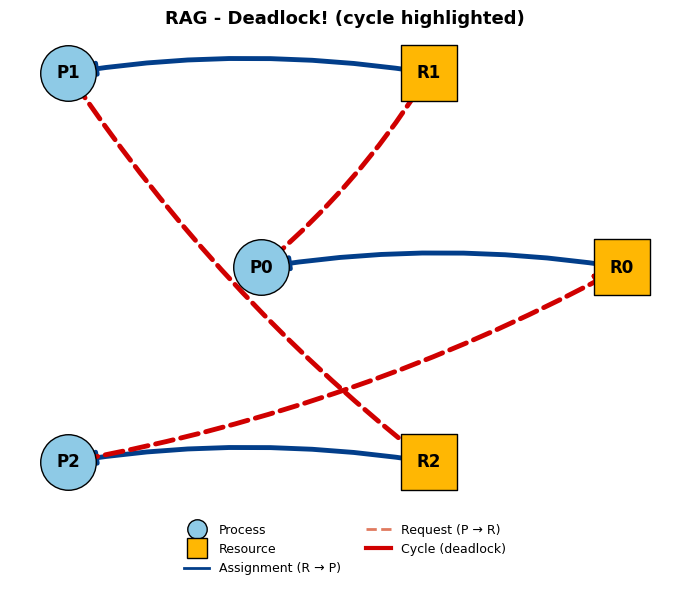

In [3]:
# Now P1 requests R2, and P2 requests R0 -> this closes a cycle P0->R1->P1->R2->P2->R0->P0
request = [
    [0, 1, 0],
    [0, 0, 1],
    [1, 0, 0],
]

rag2 = build_rag(allocation, request)
deadlocked, cycle, wfg = cycle_detect(rag2)
print("Deadlocked?", deadlocked)
print("Cycle:", cycle)

fig = draw_rag(rag2, title="RAG - Deadlock! (cycle highlighted)", highlight_cycle=cycle)
plt.savefig('../images/rag_deadlock.png', dpi=150, bbox_inches='tight')
plt.show()


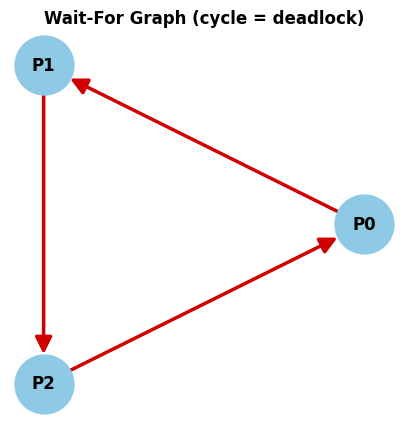

In [4]:
# The collapsed Wait-For Graph makes the cycle even clearer
fig, ax = plt.subplots(figsize=(5, 5))
import networkx as nx
pos = nx.circular_layout(wfg)
nx.draw(wfg, pos, ax=ax, with_labels=True, node_color='#8ecae6', node_size=1800,
        edge_color='#d00000', width=2.5, arrowsize=25, font_weight='bold')
ax.set_title('Wait-For Graph (cycle = deadlock)', fontweight='bold')
plt.savefig('../images/wait_for_graph.png', dpi=150, bbox_inches='tight')
plt.show()


## 2. Banker's Algorithm — Deadlock Avoidance

Instead of letting the system reach the deadlocked state above, the Banker's Algorithm
checks *before granting any request* whether doing so would leave the system in a
state from which all processes can still eventually finish (a **safe state**).

We use the classic Silberschatz textbook example: 5 processes, 3 resource types.


In [5]:
total = [10, 5, 7]
allocation = [
    [0, 1, 0],
    [2, 0, 0],
    [3, 0, 2],
    [2, 1, 1],
    [0, 0, 2],
]
max_claim = [
    [7, 5, 3],
    [3, 2, 2],
    [9, 0, 2],
    [2, 2, 2],
    [4, 3, 3],
]

rs = ResourceSystem(total, allocation, max_claim)
print("Available:", rs.available)
print("Need matrix:", rs.need())

safe, seq = rs.is_safe_state(verbose=True)
print("\nCurrent state safe?", safe)
print("Safe sequence:", seq)


Available: [3, 3, 2]
Need matrix: [[7, 4, 3], [1, 2, 2], [6, 0, 0], [0, 1, 1], [4, 3, 1]]
  P1 can finish -> work becomes [5, 3, 2]
  P3 can finish -> work becomes [7, 4, 3]
  P4 can finish -> work becomes [7, 4, 5]
  P0 can finish -> work becomes [7, 5, 5]
  P2 can finish -> work becomes [10, 5, 7]

Current state safe? True
Safe sequence: ['P1', 'P3', 'P4', 'P0', 'P2']


In [6]:
# P1 requests (1, 0, 2) -- a request the Banker's algorithm should GRANT
granted, reason, seq = rs.request_resources(1, [1, 0, 2])
print("Granted:", granted)
print("Reason:", reason)
print("New available:", rs.available)


[Banker's] Granted [1, 0, 2] to P1. Safe sequence: ['P1', 'P3', 'P4', 'P0', 'P2']
Granted: True
Reason: Request granted. System remains in a safe state.
New available: [2, 3, 0]


In [7]:
# Now P0 requests (0, 2, 0) -- watch the Banker's Algorithm REFUSE an unsafe request
granted, reason, seq = rs.request_resources(0, [0, 2, 0])
print("Granted:", granted)
print("Reason:", reason)
print("(State is unchanged because the request was denied)")
print("Available still:", rs.available)


Granted: False
Reason: Granting P0's request would lead to an UNSAFE state. Request denied.
(State is unchanged because the request was denied)
Available still: [2, 3, 0]


## 3. Deadlock Detection (when avoidance is NOT used)

Many real systems don't run Banker's Algorithm on every request (too conservative /
expensive). Instead they let processes request freely and periodically run a
**detection** algorithm. For multi-instance resources this is a matrix-reduction
algorithm very similar to Banker's safety check, but working off *actual current
requests* rather than *declared maximums*.


In [8]:
# Deliberately construct a deadlocked multi-instance state:
# P0 and P2 can finish immediately: everyone else is stuck forever.
available = [0, 0, 0]
allocation = [
    [0, 1, 0],   # P0
    [2, 0, 0],   # P1
    [3, 0, 3],   # P2
    [2, 1, 1],   # P3
    [0, 0, 2],   # P4
]
request = [
    [0, 0, 0],   # P0 - none, will finish
    [4, 0, 0],   # P1 - needs more R0 than will ever exist
    [0, 0, 0],   # P2 - none, will finish
    [0, 5, 0],   # P3 - needs more R1 than will ever exist
    [0, 0, 5],   # P4 - needs more R2 than will ever exist
]

deadlocked, finish_order = detect_deadlock_multi_instance(available, allocation, request)
print("Finished normally:", finish_order)
print("DEADLOCKED processes:", deadlocked)


Finished normally: ['P0', 'P2']
DEADLOCKED processes: ['P1', 'P3', 'P4']


## 4. Cost-Based Victim Selection — Deadlock Recovery

Once we know **which** processes are deadlocked, the system must break the cycle by
aborting or preempting one of them. Rather than choosing arbitrarily, we rank
candidates using a normalized, weighted **cost function**:

| Factor | Weight | Meaning |
|---|---|---|
| CPU time used | +0.30 | more computation thrown away = costlier |
| Priority | +0.25 | high-priority processes are costlier to kill |
| Resources held | +0.15 | holding more units (tunable trade-off) |
| Progress (0-1) | +0.20 | near-complete work is costlier to lose |
| Interactive | +0.05 | user-facing processes penalized |
| Num. restarts | -0.15 | already-sacrificed processes are protected (avoid starvation) |

The **lowest total cost** process is chosen as the victim — cheapest to sacrifice.


In [9]:
profiles = [
    ProcessProfile("P1", cpu_time_used=120, priority=8, resources_held=2, progress=0.85, interactive=True),
    ProcessProfile("P3", cpu_time_used=5,   priority=2, resources_held=4, progress=0.10, interactive=False),
    ProcessProfile("P4", cpu_time_used=40,  priority=4, resources_held=2, progress=0.45, interactive=False),
]

ranked = compute_costs(profiles)
print("Ranked victims (cheapest/best first):\n")
for name, total_cost, breakdown in ranked:
    print(f"  {name}: total_cost = {total_cost:.3f}")
    for factor, contribution in breakdown.items():
        print(f"      {factor:16s}: {contribution:+.3f}")
    print()

victim, cost, _ = select_victim(profiles)
print(f"==> Chosen victim: {victim} (cost = {cost:.3f})")


Ranked victims (cheapest/best first):

  P3: total_cost = 0.150
      cpu_time_used   : +0.000
      priority        : +0.000
      resources_held  : +0.150
      progress        : +0.000
      interactive     : +0.000
      num_restarts    : -0.000

  P4: total_cost = 0.268
      cpu_time_used   : +0.091
      priority        : +0.083
      resources_held  : +0.000
      progress        : +0.093
      interactive     : +0.000
      num_restarts    : -0.000

  P1: total_cost = 0.800
      cpu_time_used   : +0.300
      priority        : +0.250
      resources_held  : +0.000
      progress        : +0.200
      interactive     : +0.050
      num_restarts    : -0.000

==> Chosen victim: P3 (cost = 0.150)


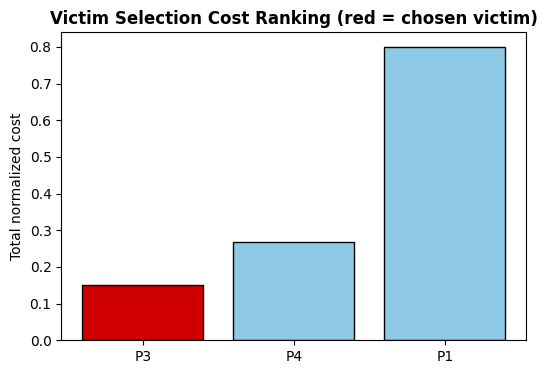

In [10]:
# Bar chart of total costs -- visually confirms the cheapest victim
fig, ax = plt.subplots(figsize=(6, 4))
names = [r[0] for r in ranked]
costs = [r[1] for r in ranked]
colors = ['#d00000' if i == 0 else '#8ecae6' for i in range(len(names))]
ax.bar(names, costs, color=colors, edgecolor='black')
ax.set_ylabel('Total normalized cost')
ax.set_title('Victim Selection Cost Ranking (red = chosen victim)', fontweight='bold')
plt.savefig('../images/victim_cost_ranking.png', dpi=150, bbox_inches='tight')
plt.show()


In [11]:
# Full automated recovery: abort victims one-by-one until the deadlock clears.
profile_map = {p.name: p for p in profiles}

# Reconstruct the deadlocked ResourceSystem state for P1, P3, P4 (single-instance style
# so we can re-check with cycle_detect after each abort)
alloc2 = [[1,0,0],[0,1,0],[0,0,1]]
req2   = [[0,1,0],[0,0,1],[1,0,0]]
rs2 = ResourceSystem(total=[1,1,1], allocation=alloc2, max_claim=[[1,1,0],[0,1,1],[1,0,1]],
                      process_names=["P1","P3","P4"])

def detect_fn():
    rag_now = build_rag(rs2.allocation, req2)
    return cycle_detect(rag_now)[:2]

aborted = recover_until_safe(["P1", "P3", "P4"], profile_map, rs2, detect_fn, verbose=True)
print("\nRecovery order (victim, cost):", aborted)


[Recovery] Ranked victims (cheapest first): [('P3', 0.15), ('P4', 0.268), ('P1', 0.8)]
[Recovery] Aborting P3 (cost=0.150) to break the cycle.
[Recovery] Deadlock resolved.

Recovery order (victim, cost): [('P3', 0.15)]


## 5. Full Simulation — Avoidance ON vs OFF

Finally, we run the **same sequence of resource requests** through two systems:
one that checks every request with Banker's Algorithm (avoidance ON), and one that
grants requests blindly (avoidance OFF) and only detects the deadlock after the fact.


In [12]:
def run_scenario(use_avoidance):
    total = [3, 3, 2]
    allocation = [[1,0,0],[0,1,0],[0,0,0]]
    max_claim  = [[2,1,1],[1,2,1],[2,2,2]]
    rs = ResourceSystem(total, allocation, max_claim, process_names=["P0","P1","P2"])

    requests_sequence = [
        (1, [0,1,0]),   # P1 wants R1 (held by P1 itself is fine, but let's make it request R0 held by P0 style)
        (0, [0,0,1]),
        (2, [1,0,0]),
    ]
    print(f"--- Avoidance {'ON' if use_avoidance else 'OFF'} ---")
    for proc, req in requests_sequence:
        if use_avoidance:
            granted, reason, seq = rs.request_resources(proc, req)
            print(f"  P{proc} requests {req}: granted={granted} | {reason}")
        else:
            # blindly grant if resources are numerically available (no safety check)
            if all(req[j] <= rs.available[j] for j in range(len(req))):
                for j in range(len(req)):
                    rs.available[j] -= req[j]
                    rs.allocation[proc][j] += req[j]
                print(f"  P{proc} requests {req}: granted (no safety check performed)")
            else:
                print(f"  P{proc} requests {req}: must wait (not enough available)")
    print("  Final allocation:", rs.allocation)
    print("  Final available:", rs.available)
    return rs

rs_avoid = run_scenario(use_avoidance=True)
print()
rs_no_avoid = run_scenario(use_avoidance=False)


--- Avoidance ON ---


[Banker's] Granted [0, 1, 0] to P1. Safe sequence: ['P0', 'P1', 'P2']
  P1 requests [0, 1, 0]: granted=True | Request granted. System remains in a safe state.
[Banker's] Granted [0, 0, 1] to P0. Safe sequence: ['P0', 'P1', 'P2']
  P0 requests [0, 0, 1]: granted=True | Request granted. System remains in a safe state.
[Banker's] Granted [1, 0, 0] to P2. Safe sequence: ['P0', 'P1', 'P2']
  P2 requests [1, 0, 0]: granted=True | Request granted. System remains in a safe state.
  Final allocation: [[1, 0, 1], [0, 2, 0], [1, 0, 0]]
  Final available: [1, 1, 1]

--- Avoidance OFF ---
  P1 requests [0, 1, 0]: granted (no safety check performed)
  P0 requests [0, 0, 1]: granted (no safety check performed)
  P2 requests [1, 0, 0]: granted (no safety check performed)
  Final allocation: [[1, 0, 1], [0, 2, 0], [1, 0, 0]]
  Final available: [1, 1, 1]


## Summary

- **RAG visualization** makes the request/assignment structure of the system visible at a glance, and cycles (potential deadlocks) can be spotted immediately.
- **Banker's Algorithm** prevents the system from ever entering an unsafe state — the price is that some requests are delayed even though a deadlock might not have actually occurred.
- **Detection algorithms** (cycle-based for single-instance, matrix-reduction for multi-instance) let a more permissive system find out *after the fact* that it is stuck.
- **Cost-based victim selection** ensures that when recovery is necessary, the process sacrificed is the one that loses the least (cheapest CPU time, lowest priority, least progress, etc.), which is far better than an arbitrary/random kill.

Together these form a complete lifecycle: **prevent → detect → recover**, which is exactly how real operating systems reason about deadlocks.
